In [1]:
from src.config import RESULT_DIR

import pandas as pd

df = pd.read_json(RESULT_DIR / 'results.jsonl', lines=True)


/home/cyaiche/generated_text_detection_hub/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-09-01 09:53:49.858 | INFO     | src.config:<module>:12 - PROJ_ROOT path is: /home/cyaiche/generated_text_detection_hub


# GRU v1 vs v2
displaying differences between the gru features with only 3 caterogy and only Assertion with subjectivity value and gru features with 5 category and three of them with subjectivity value

In [64]:
gruV1 = "3b87da9b4563a2a9cbc26ed4a4250cfc"
gruV2 ="d6376b9dc6e2d2478cdf46ec625d23b3"

In [65]:
df_gruV1 = df[df['hash'] == gruV1]
df_gruV2 = df[df['hash'] == gruV2]

In [2]:
def get_score(df, hash, label):
    df_gru = df[df['hash'] == hash]
    return (df_gru['y_true'].tolist()[0], df_gru['y_scores'].tolist()[0], label)

In [3]:
def get_score_2(df_gru, label):
    print(df_gru.columns)
    print(df_gru['y_true'].tolist())
    return (df_gru['y_true'].tolist()[0], df_gru['y_scores'].tolist()[0], label)

In [68]:
gruV1_y_true = df_gruV1['y_true'].tolist()[0]
gruv1_y_score = df_gruV1['y_scores'].tolist()[0]
gruV2_y_true = df_gruV2['y_true'].tolist()[0]
gruv2_y_score = df_gruV2['y_scores'].tolist()[0]

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_curve, auc


def roc_compare(curves,
                fpr_budgets=(0.01, 0.05, 0.10),
                title="ROC comparison",
                logx=False,
                figsize=(6.5, 6.5)):
    """
    curves : liste de tuples
        (y_true, y_score, label) ou (y_true, y_score, label, inverted: bool)
    Retourne : liste de dicts {curve, auc, budget, fpr, tpr, threshold}
               (directement consommable par pd.DataFrame).
    """
    fpr_budgets = np.atleast_1d(fpr_budgets)
    markers = ["o", "s", "^", "D", "v", "P", "X"]
    colors = plt.cm.tab10(np.linspace(0, 1, 10))

    plt.figure(figsize=figsize)
    plt.plot([0, 1], [0, 1], "k--", alpha=0.4, lw=1)
    records = []

    for i, curve in enumerate(curves):
        y_true, y_score, name = curve[0], curve[1], curve[2]
        inv = curve[3] if len(curve) > 3 else False

        s = -np.asarray(y_score, float) if inv else np.asarray(y_score, float)
        fpr, tpr, thr = roc_curve(y_true, s)
        roc_auc = auc(fpr, tpr)
        c = colors[i % len(colors)]
        plt.plot(fpr, tpr, color=c, lw=1.6, label=f"{name} (AUC={roc_auc:.4f})")

        for j, budget in enumerate(fpr_budgets):
            admissible = np.where(fpr <= budget)[0]
            if admissible.size == 0:
                print(f"[skip] {name}: aucun point sous FPR={budget:.2%} "
                      f"(FPR min = {fpr[fpr > 0].min():.4f})")
                continue
            idx = admissible[-1]  # tpr croissant => dernier indice admissible = meilleur TPR
            thr_native = -thr[idx] if inv else thr[idx]
            plt.scatter([fpr[idx]], [tpr[idx]], color=c,
                        marker=markers[j % len(markers)],
                        s=55, zorder=5, edgecolor="k", linewidth=0.6)
            records.append(dict(curve=name, auc=roc_auc, budget=budget,
                                fpr=fpr[idx], tpr=tpr[idx], threshold=thr_native))

    for budget in fpr_budgets:
        plt.axvline(budget, color="gray", ls=":", alpha=0.5)

    # Double légende : courbes (couleurs) + budgets (marqueurs)
    leg_curves = plt.legend(loc="lower right", fontsize=9)
    plt.gca().add_artist(leg_curves)
    budget_handles = [Line2D([], [], color="gray", marker=markers[j % len(markers)],
                             ls="none", markeredgecolor="k",
                             label=f"TPR@{b:.0%}FPR")
                      for j, b in enumerate(fpr_budgets)]
    plt.legend(handles=budget_handles, loc="center right", fontsize=8)

    if logx:
        plt.xscale("log")
        plt.xlim(left=max(1e-4, min(fpr_budgets) / 10))
    plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.title(title); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    # Tableau récapitulatif
    print(f"{'curve':<25} {'AUC':>8} {'budget':>8} {'TPR':>8} {'FPR_eff':>9} {'thr':>12}")
    for r in sorted(records, key=lambda r: (r["budget"], -r["tpr"])):
        print(f"{r['curve']:<25} {r['auc']:>8.4f} {r['budget']:>8.0%} "
              f"{r['tpr']:>8.4f} {r['fpr']:>9.4f} {r['threshold']:>12.6f}")
    return records

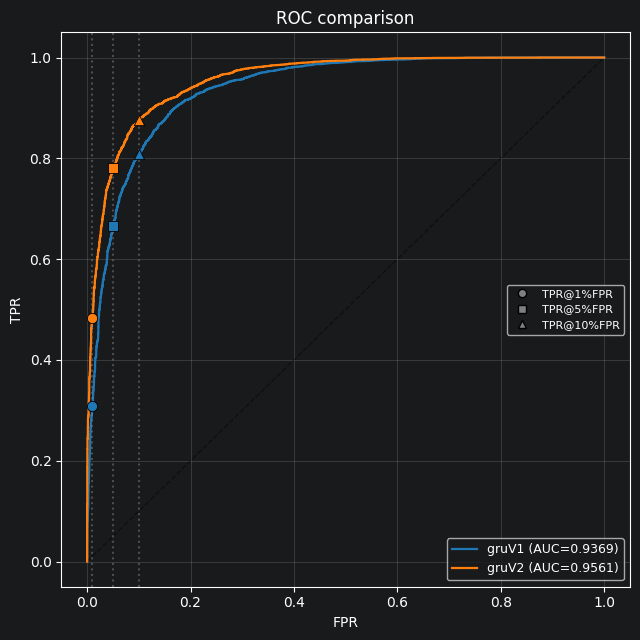

curve                          AUC   budget      TPR   FPR_eff          thr
gruV2                       0.9561       1%   0.4834    0.0099     0.952155
gruV1                       0.9369       1%   0.3088    0.0099     0.935806
gruV2                       0.9561       5%   0.7818    0.0500     0.797905
gruV1                       0.9369       5%   0.6650    0.0500     0.795743
gruV2                       0.9561      10%   0.8768    0.0999     0.638090
gruV1                       0.9369      10%   0.8090    0.0999     0.649825


[{'curve': 'gruV1',
  'auc': 0.9368767179023508,
  'budget': np.float64(0.01),
  'fpr': np.float64(0.009945750452079566),
  'tpr': np.float64(0.3088),
  'threshold': np.float64(0.9358055591583251)},
 {'curve': 'gruV1',
  'auc': 0.9368767179023508,
  'budget': np.float64(0.05),
  'fpr': np.float64(0.049954792043399636),
  'tpr': np.float64(0.665),
  'threshold': np.float64(0.7957432270050041)},
 {'curve': 'gruV1',
  'auc': 0.9368767179023508,
  'budget': np.float64(0.1),
  'fpr': np.float64(0.09990958408679927),
  'tpr': np.float64(0.809),
  'threshold': np.float64(0.6498247981071471)},
 {'curve': 'gruV2',
  'auc': 0.9560794529837251,
  'budget': np.float64(0.01),
  'fpr': np.float64(0.009945750452079566),
  'tpr': np.float64(0.4834),
  'threshold': np.float64(0.9521549344062801)},
 {'curve': 'gruV2',
  'auc': 0.9560794529837251,
  'budget': np.float64(0.05),
  'fpr': np.float64(0.049954792043399636),
  'tpr': np.float64(0.7818),
  'threshold': np.float64(0.7979049682617181)},
 {'curve'

In [70]:
roc_compare([(gruV1_y_true, gruv1_y_score, "gruV1"), (gruV2_y_true, gruv2_y_score, "gruV2")])

# SAGE 2 step comparaison

Index(['hash', 'name', 'seed', 'hardware.device', 'dataset.name',
       'dataset.description', 'dataset.conference', 'dataset.date',
       'dataset.keep_meta', 'dataset.subset_size', 'dataset.split',
       'dataset.with_pdf', 'dataset.seed', 'data_loader.batch_size',
       'data_loader.num_workers', 'data_loader.pin_memory', 'detector.name',
       'detector.type', 'detector.params.seed', 'auroc', 'tpr_5_fpr',
       'tpr_1_fpr', 'precision', 'recall', 'f1_score', 'accuracy', 'y_true',
       'y_scores', 'experiment.eval.detector.name',
       'experiment.eval.detector.type', 'experiment.eval.detector.trainable',
       'experiment.eval.detector.params.scoring_model_name',
       'experiment.eval.detector.params.n_perturbation',
       'experiment.eval.detector.params.mask_filling_model_name',
       'experiment.eval.detector.params.pct_words_masked',
       'experiment.eval.detector.params.span_length',
       'experiment.eval.detector.params.mask_top_p',
       'experiment.eval.h

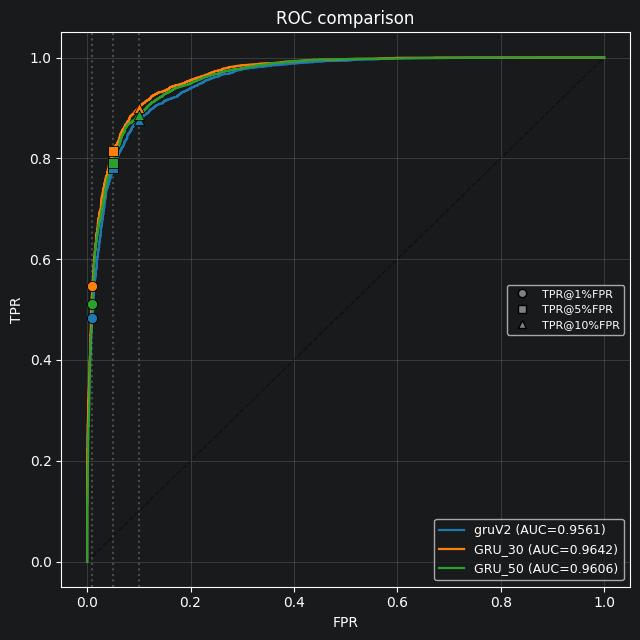

curve                          AUC   budget      TPR   FPR_eff          thr
GRU_30                      0.9642       1%   0.5464    0.0099     0.952317
GRU_50                      0.9606       1%   0.5110    0.0099     0.962560
gruV2                       0.9561       1%   0.4834    0.0099     0.952155
GRU_30                      0.9642       5%   0.8144    0.0500     0.782520
GRU_50                      0.9606       5%   0.7908    0.0500     0.733761
gruV2                       0.9561       5%   0.7818    0.0500     0.797905
GRU_30                      0.9642      10%   0.9008    0.0995     0.574886
GRU_50                      0.9606      10%   0.8860    0.0997     0.463642
gruV2                       0.9561      10%   0.8768    0.0999     0.638090


[{'curve': 'gruV2',
  'auc': 0.9560794529837251,
  'budget': np.float64(0.01),
  'fpr': np.float64(0.009945750452079566),
  'tpr': np.float64(0.4834),
  'threshold': np.float64(0.9521549344062801)},
 {'curve': 'gruV2',
  'auc': 0.9560794529837251,
  'budget': np.float64(0.05),
  'fpr': np.float64(0.049954792043399636),
  'tpr': np.float64(0.7818),
  'threshold': np.float64(0.7979049682617181)},
 {'curve': 'gruV2',
  'auc': 0.9560794529837251,
  'budget': np.float64(0.1),
  'fpr': np.float64(0.09990958408679927),
  'tpr': np.float64(0.8768),
  'threshold': np.float64(0.6380897164344781)},
 {'curve': 'GRU_30',
  'auc': 0.964228616636528,
  'budget': np.float64(0.01),
  'fpr': np.float64(0.009945750452079566),
  'tpr': np.float64(0.5464),
  'threshold': np.float64(0.952316999435424)},
 {'curve': 'GRU_30',
  'auc': 0.964228616636528,
  'budget': np.float64(0.05),
  'fpr': np.float64(0.049954792043399636),
  'tpr': np.float64(0.8144),
  'threshold': np.float64(0.782520115375518)},
 {'curve'

In [71]:
gruV2_30_50 = "580ae5ecf6642c478de600cb70fdba34"
df_gruV2_30_50 = df[df['hash'] == gruV2_30_50]
df_gruV2_30 = df_gruV2_30_50[df_gruV2_30_50['training.model.params_training.epochs'] == 30]
df_gruV2_50 = df_gruV2_30_50[df_gruV2_30_50['training.model.params_training.epochs'] == 50]
gru30_y_tuple = get_score_2(df_gruV2_30, "GRU_30")
gru50_y_tuple = get_score_2(df_gruV2_50, "GRU_50")
gru15_y_tuple =  (gruV2_y_true, gruv2_y_score, "gruV2")
list = [gru15_y_tuple, gru30_y_tuple, gru50_y_tuple]
roc_compare(list)

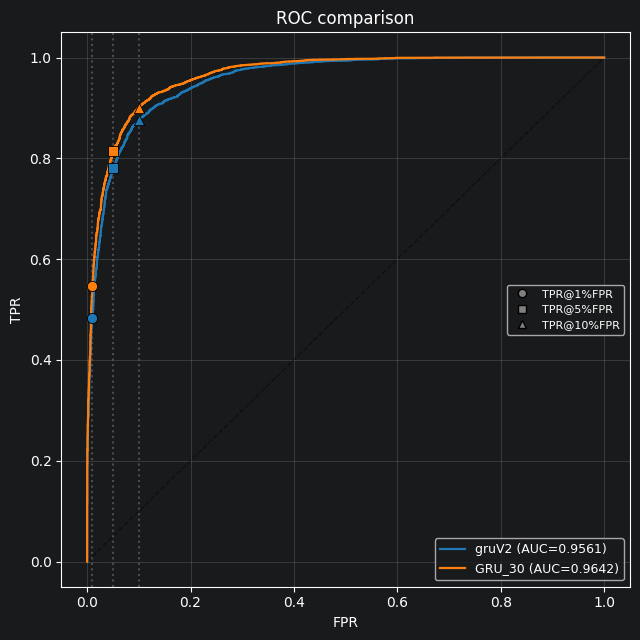

curve                          AUC   budget      TPR   FPR_eff          thr
GRU_30                      0.9642       1%   0.5464    0.0099     0.952317
gruV2                       0.9561       1%   0.4834    0.0099     0.952155
GRU_30                      0.9642       5%   0.8144    0.0500     0.782520
gruV2                       0.9561       5%   0.7818    0.0500     0.797905
GRU_30                      0.9642      10%   0.9008    0.0995     0.574886
gruV2                       0.9561      10%   0.8768    0.0999     0.638090


[{'curve': 'gruV2',
  'auc': 0.9560794529837251,
  'budget': np.float64(0.01),
  'fpr': np.float64(0.009945750452079566),
  'tpr': np.float64(0.4834),
  'threshold': np.float64(0.9521549344062801)},
 {'curve': 'gruV2',
  'auc': 0.9560794529837251,
  'budget': np.float64(0.05),
  'fpr': np.float64(0.049954792043399636),
  'tpr': np.float64(0.7818),
  'threshold': np.float64(0.7979049682617181)},
 {'curve': 'gruV2',
  'auc': 0.9560794529837251,
  'budget': np.float64(0.1),
  'fpr': np.float64(0.09990958408679927),
  'tpr': np.float64(0.8768),
  'threshold': np.float64(0.6380897164344781)},
 {'curve': 'GRU_30',
  'auc': 0.964228616636528,
  'budget': np.float64(0.01),
  'fpr': np.float64(0.009945750452079566),
  'tpr': np.float64(0.5464),
  'threshold': np.float64(0.952316999435424)},
 {'curve': 'GRU_30',
  'auc': 0.964228616636528,
  'budget': np.float64(0.05),
  'fpr': np.float64(0.049954792043399636),
  'tpr': np.float64(0.8144),
  'threshold': np.float64(0.782520115375518)},
 {'curve'

In [72]:
list = [gru15_y_tuple, gru30_y_tuple]
roc_compare(list)

In [73]:
df_gruV2_30

,hash,name,seed,hardware.device,dataset.name,dataset.description,dataset.conference,dataset.date,dataset.keep_meta,dataset.subset_size,...,training.model.method,training.model.params_model.n_features,training.model.params_model.hidden,training.model.params_model.n_layers,training.model.params_training.epochs,training.model.params_training.lr,training.model.batch_size,training.model.feature_version.segmentation,training.model.feature_version.subj_category,ids
17,580ae5ecf6642c478de600cb70fdba34,gru,42,cuda:0,aprdb,"AI Peer Review Detection Benchmark, test subse...",NaN,NaN,True,10000,...,training,7.0,32.0,1.0,30.0,0.001,64.0,2.0,"[Assertion, Expressive, Question, Suggestion]",NaN


In [6]:
v_10 = get_score(df, "39c7abadd1e7be3a6576804940192347", "cristal anchor 10")
v_60 = get_score(df, "f2e28a66ccdc98e981c69a2340e96ef7", "cristal anchor 60")
v_600 = get_score(df, "52ecb010d4aada09d805335eaaa54b88", "cristal anchor 600")
l = [v_10, v_60, v_600]

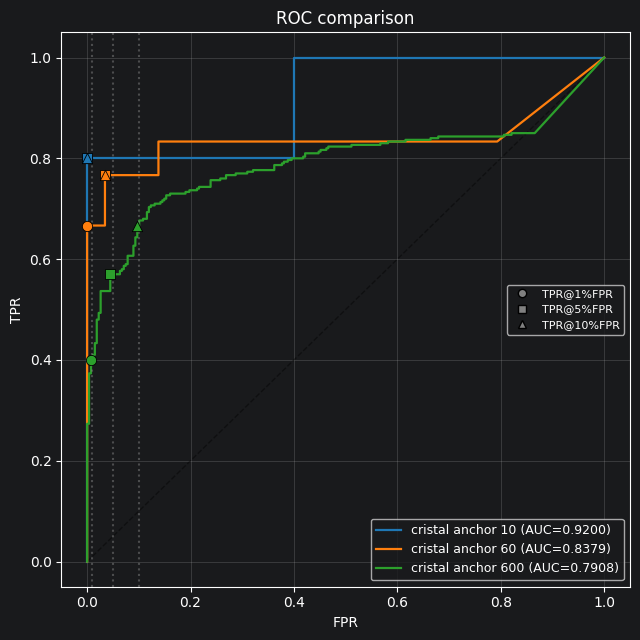

curve                          AUC   budget      TPR   FPR_eff          thr
cristal anchor 10           0.9200       1%   0.8000    0.0000     0.837052
cristal anchor 60           0.8379       1%   0.6667    0.0000     0.794332
cristal anchor 600          0.7908       1%   0.4000    0.0075     0.861341
cristal anchor 10           0.9200       5%   0.8000    0.0000     0.837052
cristal anchor 60           0.8379       5%   0.7667    0.0345     0.774724
cristal anchor 600          0.7908       5%   0.5700    0.0448     0.831818
cristal anchor 10           0.9200      10%   0.8000    0.0000     0.837052
cristal anchor 60           0.8379      10%   0.7667    0.0345     0.774724
cristal anchor 600          0.7908      10%   0.6667    0.0970     0.802846


[{'curve': 'cristal anchor 10',
  'auc': 0.92,
  'budget': np.float64(0.01),
  'fpr': np.float64(0.0),
  'tpr': np.float64(0.8),
  'threshold': np.float64(0.837051808834075)},
 {'curve': 'cristal anchor 10',
  'auc': 0.92,
  'budget': np.float64(0.05),
  'fpr': np.float64(0.0),
  'tpr': np.float64(0.8),
  'threshold': np.float64(0.837051808834075)},
 {'curve': 'cristal anchor 10',
  'auc': 0.92,
  'budget': np.float64(0.1),
  'fpr': np.float64(0.0),
  'tpr': np.float64(0.8),
  'threshold': np.float64(0.837051808834075)},
 {'curve': 'cristal anchor 60',
  'auc': 0.8379310344827586,
  'budget': np.float64(0.01),
  'fpr': np.float64(0.0),
  'tpr': np.float64(0.6666666666666666),
  'threshold': np.float64(0.794332444667816)},
 {'curve': 'cristal anchor 60',
  'auc': 0.8379310344827586,
  'budget': np.float64(0.05),
  'fpr': np.float64(0.034482758620689655),
  'tpr': np.float64(0.7666666666666667),
  'threshold': np.float64(0.774723768234252)},
 {'curve': 'cristal anchor 60',
  'auc': 0.837

In [7]:
roc_compare(l)

In [8]:
df = pd.read_csv("/data2/cyaiche/cache_dir/results/results_with_linguistic_features_580ae5ec.csv")

In [9]:
df

,Unnamed: 0,hash,dataset.name,dataset.split,auroc,tpr_5_fpr,tpr_1_fpr,precision,recall,f1_score,...,position,label,generator,conference,year,sentences,rule_based_SA-label,raw_prediction_1_5,rounded_prediction,predicted_label
0,0,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,0,0,claude,ICLR,2021,Pros:,Neither,NaN,NaN,NaN
1,1,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,0,0,claude,ICLR,2021,- The different attention techniques seem to c...,Assertion,1.342592,1.0,WORLD
2,2,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,0,0,claude,ICLR,2021,- The ablation studies are important in showin...,Assertion,1.891834,2.0,WORLD+VALUES
3,3,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,0,0,claude,ICLR,2021,- Please clarify if the student models start f...,Suggestion,1.559920,2.0,WORLD+VALUES
4,4,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,0,0,claude,ICLR,2021,In this regard to what extend is the approach ...,Question,1.479721,1.0,WORLD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
207698,207698,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,9423,0,claude,NeurIPS,2018,Do they yield similar performance?,Question,1.230409,1.0,WORLD
207699,207699,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,9423,0,claude,NeurIPS,2018,An MDN-RNN is used to increase the apparent st...,Assertion,1.191167,1.0,WORLD
207700,207700,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,9423,0,claude,NeurIPS,2018,"Do you think this construction is necessary, o...",Question,1.278095,1.0,WORLD
207701,207701,580ae5ecf6642c478de600cb70fdba34b5ad7993ad7d52...,aprdb,test,0.964229,0.8144,0.5464,0.896134,0.918,0.906935,...,9423,0,claude,NeurIPS,2018,Iâm curious whether itâs necessary to trai...,Expressive,3.371274,3.0,VALUES
